In [4]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

from smc_wildfire.data import (
    get_landscape_path,
    get_max_timestep,
    get_observation_path,
    load_observation,
)
from smc_wildfire.ensf import run_ensf
from smc_wildfire.farsite import run_farsite
from smc_wildfire.smc_filters import run_bootstrap_pf, run_guided_pf


In [5]:
idx_wildfire = 1819
landscape = get_landscape_path(idx_wildfire)
initial_perimeter = load_observation(idx_wildfire, idx_time=0)
crs = gpd.read_file(get_observation_path(idx_wildfire, idx_time=0)).crs

In [ ]:
"""
Boucle de filtrage EnSF
"""

rng_ensf = np.random.default_rng(2003)
# paramètres de l'article : 
num_particles = 10
num_steps = 200
eps_a = 0.96
eps_b = 0.03
C = 1 
std_obs = 0.5
std_state = np.sqrt(0.5)
std_init = 0.1

observations_ensf, filtered_particles_ensf = run_ensf(
    idx_wildfire=idx_wildfire, 
    num_particles=num_particles, 
    num_steps=num_steps, 
    eps_a=eps_a, 
    eps_b=eps_b, 
    C=C, 
    std_obs=std_obs, 
    std_state=std_state, 
    std_init=std_init,
    rng=rng_ensf
)

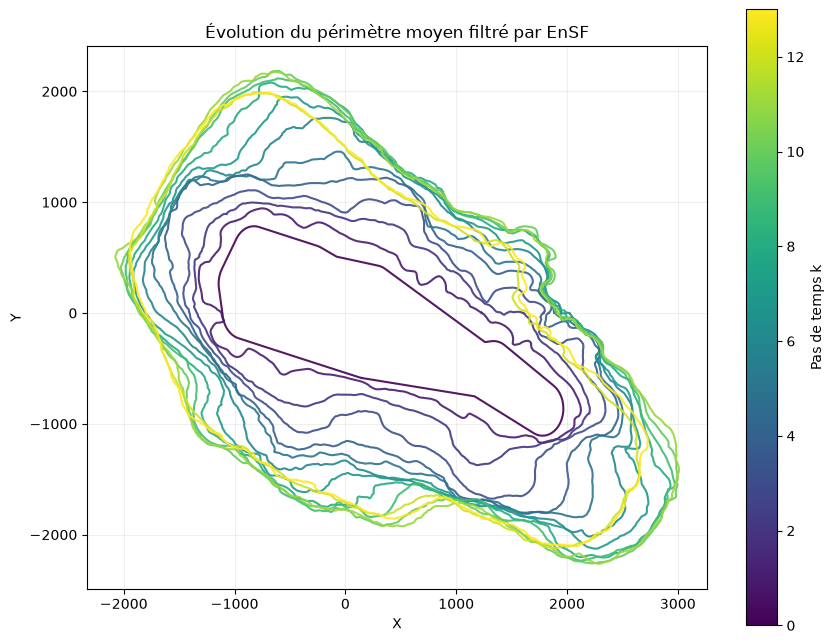

In [7]:
"""
Plot de l'évolution de l'EnSF avec moyenne des particules pour chaque pas de temps
"""

fig, ax = plt.subplots(figsize=(10, 8))

cmap = plt.colormaps["viridis"]
norm = plt.Normalize(vmin=0, vmax=len(filtered_particles_ensf)-1)

for k, particles in enumerate(filtered_particles_ensf):
    mean_filtered = particles.mean(axis=0).reshape(-1, 2)

    # Fermer le périmètre
    closed = np.vstack([mean_filtered, mean_filtered[0]])

    ax.plot(
        closed[:, 0],
        closed[:, 1],
        color=cmap(norm(k)),
        linewidth=1.5,
        alpha=0.9
    )

sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=ax, label="Pas de temps k")

ax.set_aspect("equal")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("Évolution du périmètre moyen filtré par EnSF")
ax.grid(alpha=0.2)

plt.show()

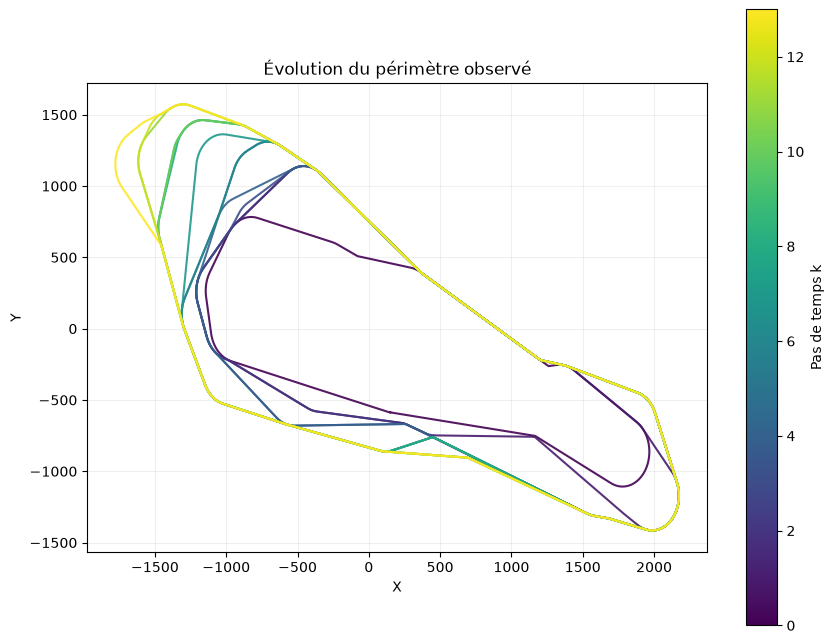

In [8]:
"""
Plot de l'évolution de l'observation
"""

fig, ax = plt.subplots(figsize=(10, 8))

cmap = plt.colormaps["viridis"]
norm = plt.Normalize(vmin=0, vmax=len(observations_ensf)-1)

for k, obs in enumerate(observations_ensf):

    # Fermer le périmètre
    closed = np.vstack([obs, obs[0]])

    ax.plot(
        closed[:, 0],
        closed[:, 1],
        color=cmap(norm(k)),
        linewidth=1.5,
        alpha=0.9
    )

sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=ax, label="Pas de temps k")

ax.set_aspect("equal")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("Évolution du périmètre observé")
ax.grid(alpha=0.2)

plt.show()

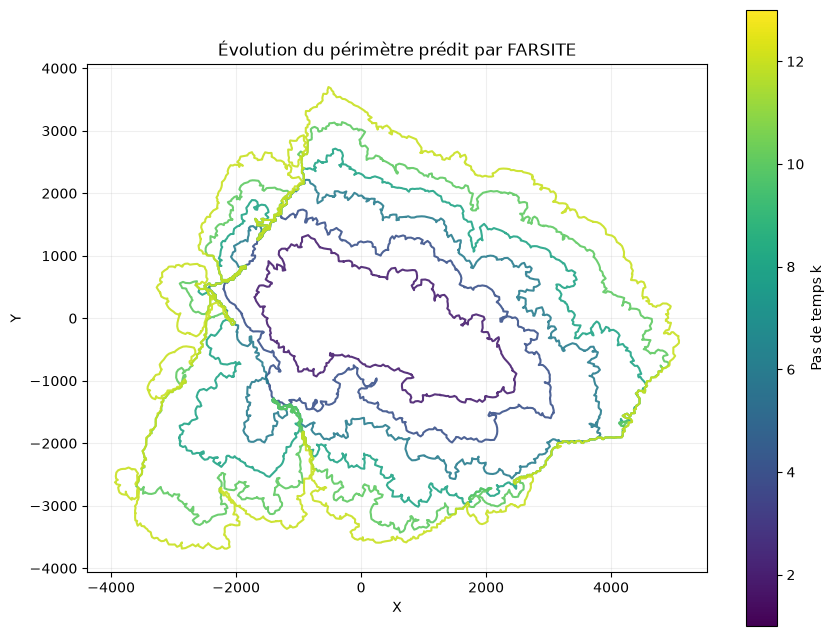

In [9]:
"""
FARSITE UNIQUEMENT : X_{k+1} = FARSITE(X_k)
"""
idx_wildfire = 1819
farsite_predictions = run_farsite(idx_wildfire)

fig, ax = plt.subplots(figsize=(10, 8))

cmap = plt.colormaps["viridis"]
norm = plt.Normalize(vmin=1, vmax=len(farsite_predictions))

for k, f_pred in enumerate(farsite_predictions, start=1):

    if k%2 == 0:
        closed = np.vstack([f_pred, f_pred[0]])

        ax.plot(
            closed[:, 0],
            closed[:, 1],
            color=cmap(norm(k)),
            linewidth=1.5,
            alpha=0.9
        )

sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=ax, label="Pas de temps k")

ax.set_aspect("equal")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("Évolution du périmètre prédit par FARSITE")
ax.grid(alpha=0.2)

plt.show()

In [10]:
"""
Boucle de filtrage BPF
"""

rng_bpf = np.random.default_rng(2000)

observations_bpf, filtered_particles_bpf, log_W_bpf, log_ESS_hist_bpf = run_bootstrap_pf(
    idx_wildfire=idx_wildfire,
    num_particles=num_particles,
    C=C,
    std_obs=std_obs,
    std_state=std_state,
    std_init=std_init,
    rng=rng_bpf
)

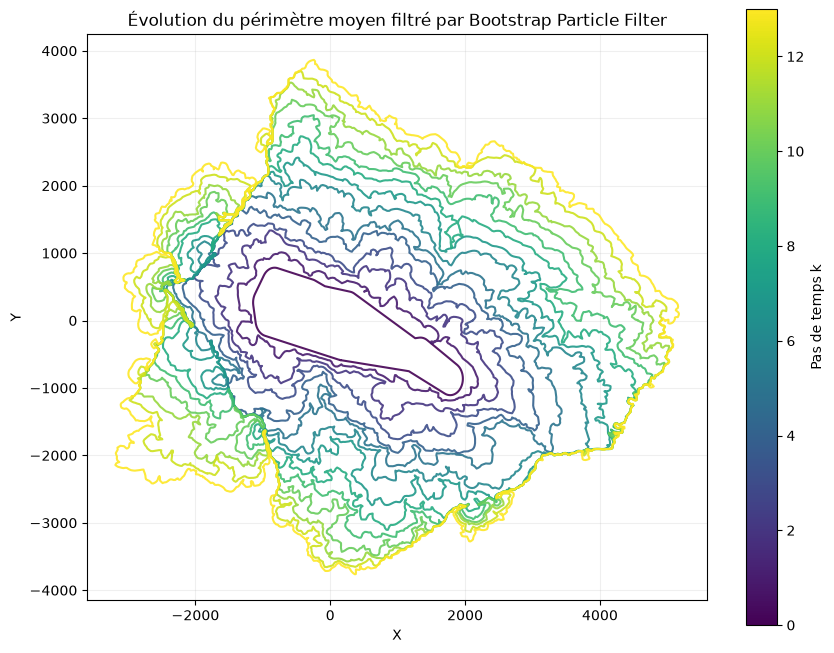

In [11]:
"""
Plot de l'évolution du BPF avec moyenne des particules pour chaque pas de temps
"""

fig, ax = plt.subplots(figsize=(10, 8))

cmap = plt.colormaps["viridis"]
norm = plt.Normalize(vmin=0, vmax=len(filtered_particles_bpf)-1)

for k, particles in enumerate(filtered_particles_bpf):
    mean_filtered = np.average(
        particles,
        axis=0,
        weights=np.exp(log_W_bpf[k])
    ).reshape(-1, 2)

    # Fermer le périmètre
    closed = np.vstack([mean_filtered, mean_filtered[0]])

    ax.plot(
        closed[:, 0],
        closed[:, 1],
        color=cmap(norm(k)),
        linewidth=1.5,
        alpha=0.9
    )

sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=ax, label="Pas de temps k")

ax.set_aspect("equal")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("Évolution du périmètre moyen filtré par Bootstrap Particle Filter")
ax.grid(alpha=0.2)

plt.show()

In [12]:
"""
Boucle de filtrage Guided PF
"""

rng_gpf = np.random.default_rng(1000)

observations_gpf, filtered_particles_gpf, log_W_gpf, log_ESS_hist_gpf = run_guided_pf(
    idx_wildfire=idx_wildfire,
    num_particles=num_particles,
    C=C,
    std_obs=std_obs,
    std_state=std_state,
    std_init=std_init,
    rng=rng_gpf
)

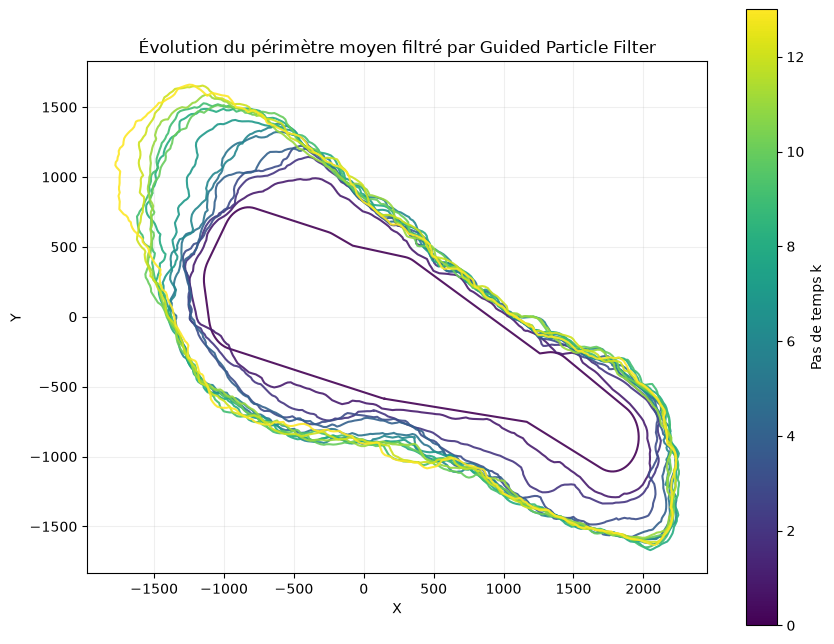

In [13]:
"""
Plot de l'évolution du GPF avec moyenne des particules pour chaque pas de temps
"""

fig, ax = plt.subplots(figsize=(10, 8))

cmap = plt.colormaps["viridis"]
norm = plt.Normalize(vmin=0, vmax=len(filtered_particles_gpf)-1)

for k, particles in enumerate(filtered_particles_gpf):
    mean_filtered = np.average(
        particles,
        axis=0,
        weights=np.exp(log_W_gpf[k])
    ).reshape(-1, 2)

    # Fermer le périmètre
    closed = np.vstack([mean_filtered, mean_filtered[0]])

    ax.plot(
        closed[:, 0],
        closed[:, 1],
        color=cmap(norm(k)),
        linewidth=1.5,
        alpha=0.9
    )

sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=ax, label="Pas de temps k")

ax.set_aspect("equal")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("Évolution du périmètre moyen filtré par Guided Particle Filter")
ax.grid(alpha=0.2)

plt.show()

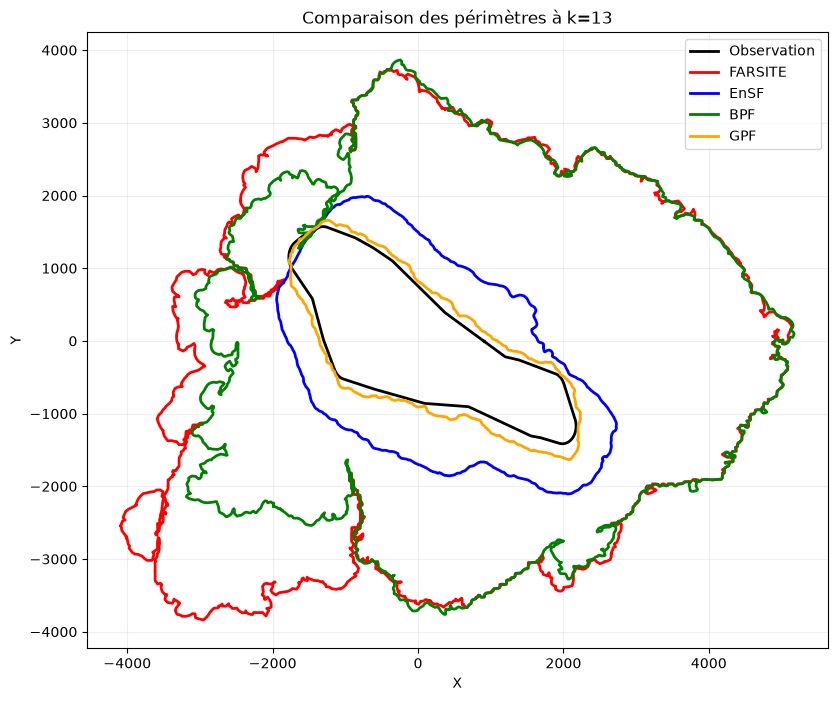

In [14]:
"""
Comparaison de X filtré via EnSF, BPF, GPF, FARSITE uniquement et l'OBS
"""

k = get_max_timestep(idx_wildfire)

Y = observations_ensf[k]
farsite_pred = farsite_predictions[k-1]

X_filtered_ensf = filtered_particles_ensf[k].mean(axis=0).reshape(-1, 2)

X_filtered_bpf = np.average(
    filtered_particles_bpf[k],
    axis=0,
    weights=np.exp(log_W_bpf[k])
).reshape(-1, 2)

X_filtered_gpf = np.average(
    filtered_particles_gpf[k],
    axis=0,
    weights=np.exp(log_W_gpf[k])
).reshape(-1, 2)

fig, ax = plt.subplots(figsize=(10, 8))

for perimeter, label, color in [
    (Y, "Observation", "black"),
    (farsite_pred, "FARSITE", "red"),
    (X_filtered_ensf, "EnSF", "blue"),
    (X_filtered_bpf, "BPF", "green"),
    (X_filtered_gpf, "GPF", "orange"),
]:
    closed = np.vstack([perimeter, perimeter[0]])
    ax.plot(
        closed[:, 0],
        closed[:, 1],
        label=label,
        color=color,
        linewidth=2,
    )

ax.set_aspect("equal")
ax.set_title(f"Comparaison des périmètres à k={k}")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.legend()
ax.grid(alpha=0.2)

plt.show()